In [4]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [5]:
url = "https://quotes.toscrape.com/"

response = requests.get(url, timeout=15)

print(response.status_code)

200


In [6]:
soup = BeautifulSoup(response.text, "html.parser")
print(soup.title.text)

Quotes to Scrape


In [8]:
# quote = soup.find("span" , class_="text")
quote = soup.find("span", class_="text")
print(quote.text)

“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”


In [10]:
quotes = soup.find_all("span", class_="text")

for quote in quotes:
    print(quote.text)

“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
“It is our choices, Harry, that show what we truly are, far more than our abilities.”
“There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”
“The person, be it gentleman or lady, who has not pleasure in a good novel, must be intolerably stupid.”
“Imperfection is beauty, madness is genius and it's better to be absolutely ridiculous than absolutely boring.”
“Try not to become a man of success. Rather become a man of value.”
“It is better to be hated for what you are than to be loved for what you are not.”
“I have not failed. I've just found 10,000 ways that won't work.”
“A woman is like a tea bag; you never know how strong it is until it's in hot water.”
“A day without sunshine is like, you know, night.”


In [27]:
quote_blocks = soup.find_all("div" , class_="quote")

for block in quote_blocks:
    quote = block.find("span", class_="text").text
    author = block.find("small",class_="author").text
    
    print("Quote:", quote)
    print("Author:", author)
    print("--------------------")


Quote: “The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
Author: Albert Einstein
--------------------
Quote: “It is our choices, Harry, that show what we truly are, far more than our abilities.”
Author: J.K. Rowling
--------------------
Quote: “There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”
Author: Albert Einstein
--------------------
Quote: “The person, be it gentleman or lady, who has not pleasure in a good novel, must be intolerably stupid.”
Author: Jane Austen
--------------------
Quote: “Imperfection is beauty, madness is genius and it's better to be absolutely ridiculous than absolutely boring.”
Author: Marilyn Monroe
--------------------
Quote: “Try not to become a man of success. Rather become a man of value.”
Author: Albert Einstein
--------------------
Quote: “It is better to be hated for what you are than to be loved for what y

In [32]:
quotes_data=[]

for block in quote_blocks:
    quote=block.find("span", class_="text").text
    author=block.find("small", class_="author").text
    quotes_data.append({
    "Qoute":quote,
    "Author":author
    })

print(quotes_data[0])

{'Qoute': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'Author': 'Albert Einstein'}


In [33]:
df=pd.DataFrame(quotes_data)
df

,Qoute,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe
5,“Try not to become a man of success. Rather be...,Albert Einstein
6,“It is better to be hated for what you are tha...,André Gide
7,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison
8,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt
9,"“A day without sunshine is like, you know, nig...",Steve Martin


In [34]:
df.to_csv("quotes_data.csv", index=False)
print("CSV file is saved Sucessfully")

CSV file is saved Sucessfully


In [35]:
saved_data = pd.read_csv("quotes_data.csv")
saved_data.head()

,Qoute,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


In [37]:
saved_data.isnull().sum()

Qoute     0
Author    0
dtype: int64

In [38]:
duplicates=saved_data.duplicated().sum()
print("Total Duplicate Records:",duplicates)

Total Duplicate Records: 0


In [39]:
author_counts = saved_data["Author"].value_counts()
print(author_counts)

Author
Albert Einstein      3
J.K. Rowling         1
Jane Austen          1
Marilyn Monroe       1
André Gide           1
Thomas A. Edison     1
Eleanor Roosevelt    1
Steve Martin         1
Name: count, dtype: int64


In [45]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 882.6 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.3 MB 958.5 kB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.3 MB 915.5 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.3 MB 915.5 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.3 MB 958.5 kB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.3 MB 1.1 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 1.1 MB/s eta 0:00:08
   ---------- ----------------------------- 2.4/9.3 MB 1.1 MB/s eta 0:00:07
   ---------- ----------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [46]:
import matplotlib.pyplot as plt

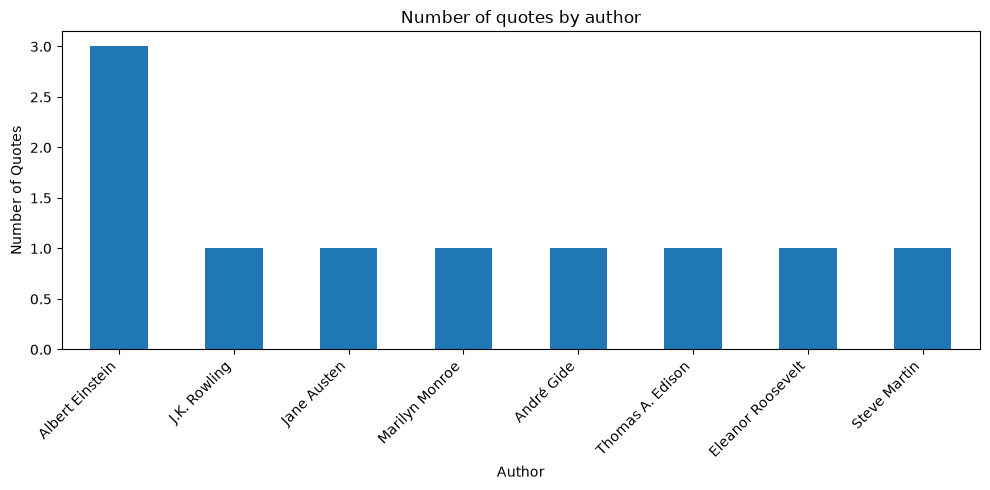

In [51]:
author_counts.plot(kind="bar", figsize=(10,5))
plt.title("Number of quotes by author")
plt.xlabel("Author")
plt.ylabel("Number of Quotes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

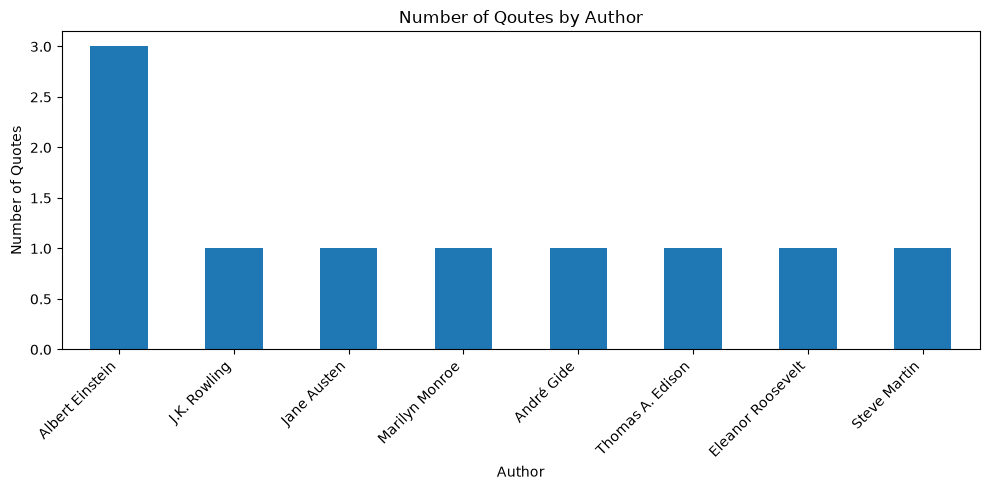

In [52]:
ax=author_counts.plot(kind="bar",figsize=(10,5))

plt.title("Number of Qoutes by Author")
plt.xlabel("Author")
plt.ylabel("Number of Quotes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("author_quotes_chart.png",dpi=300)
plt.show()

In [54]:
for page in range(1,4):
        url = f"https://quotes.toscrape.com/page/{page}/"
        print(url)

https://quotes.toscrape.com/page/1/
https://quotes.toscrape.com/page/2/
https://quotes.toscrape.com/page/3/


In [61]:
# all_quotes = []
# for page in range(1,4 ):
#         url = f"https://quotes.toscrape.com/page/{page}/"
#         response = requests.get(url, timeout=15)
#         response.raise_for_status()
#         soup = BeautifulSoup(response.text,"html.parser")
#         qoute_blocks=soup.find_all("div", class_="quote")

# for block in quote_blocks:
#         quote=block.find("span", class_="text").text
#         author=block.find("small",class_="author").text
        
#         all_quotes.append({
#             "Quote":quote,
#             "Author":author
#         })
# print(f"page {page}:{len(quote_blocks)}quotes extracted")
# print("Total Quotes:", len(all_quotes))
all_quotes = []

for page in range(1, 4):
    url = f"https://quotes.toscrape.com/page/{page}/"

    response = requests.get(url, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    quote_blocks = soup.find_all("div", class_="quote")

    for block in quote_blocks:
        quote = block.find("span", class_="text").text
        author = block.find("small", class_="author").text

        all_quotes.append({
            "Quote": quote,
            "Author": author
        })

    print(f"Page {page}: {len(quote_blocks)} quotes extracted")

print("Total Quotes:", len(all_quotes))

Page 1: 10 quotes extracted
Page 2: 10 quotes extracted
Page 3: 10 quotes extracted
Total Quotes: 30


In [63]:
df_all=pd.DataFrame(all_quotes)

# save data to CSV
df_all.to_csv("all_quotes.csv",index=False)

# Display first 5 record
df_all.head()

,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


In [69]:
all_quotes = []
page = 1

while True:
    url = f"https://quotes.toscrape.com/page/{page}/"

    response = requests.get(url, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    quote_blocks = soup.find_all("div", class_="quote")

    for block in quote_blocks:
        quote = block.find("span", class_="text").text
        author = block.find("small", class_="author").text

        all_quotes.append({
            "Quote": quote,
            "Author": author
        })

    print(f"Page {page}: {len(quote_blocks)} quotes")

    next_button = soup.find("li", class_="next")

    if next_button is None:
        break

    page += 1

print("Total Quotes:", len(all_quotes))

Page 1: 10 quotes
Page 2: 10 quotes
Page 3: 10 quotes
Page 4: 10 quotes
Page 5: 10 quotes
Page 6: 10 quotes
Page 7: 10 quotes
Page 8: 10 quotes
Page 9: 10 quotes
Page 10: 10 quotes
Total Quotes: 100


In [70]:
# convert the all  qoutes into DataFrame

df_complete = pd.DataFrame(all_quotes)

# save the complete data set

df_complete.to_csv("complete_quotes.csv",index=False)

# Check total records
print("Total Records:", len(df_complete))

print("CSV file saved successfully!")

Total Records: 100
CSV file saved successfully!


In [74]:
# Total number of Quotes
print("Total Quotes:", len(df_complete))

# Total unique authors:
print("unique Authors:", df_complete["Author"].nunique())

# Top 10 authors with most quotes
top_authors = df_complete["Author"].value_counts().head(10)

print("\n Top 10 Authors")
print(top_authors)

Total Quotes: 100
unique Authors: 50

 Top 10 Authors
Author
Albert Einstein        10
J.K. Rowling            9
Marilyn Monroe          7
Dr. Seuss               6
Mark Twain              6
Jane Austen             5
C.S. Lewis              5
Bob Marley              3
Eleanor Roosevelt       2
Ralph Waldo Emerson     2
Name: count, dtype: int64


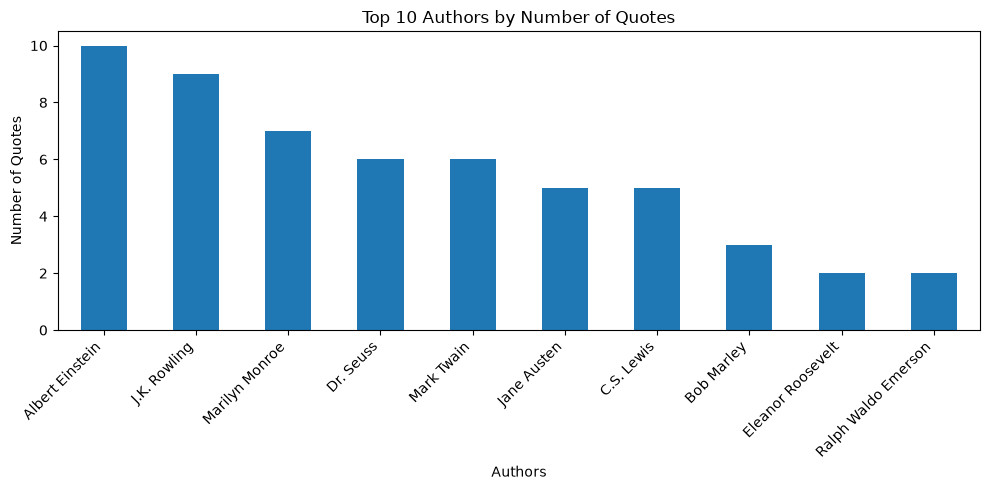

In [75]:
import matplotlib.pyplot as plt

top_authors.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Authors by Number of Quotes")
plt.xlabel("Authors")
plt.ylabel("Number of Quotes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("top_10_authors.png", dpi=300)
plt.show()

In [79]:
print("Total Records:",len(df_complete))

print("\n Missing Values:")
print(df_complete.isnull().sum())

print("\n Duplicate Records:")
print(df_complete.duplicated().sum())

Total Records: 100

 Missing Values:
Quote     0
Author    0
dtype: int64

 Duplicate Records:
0


In [81]:
author_name=input("Enter author name: ")

results=df_complete[
    df_complete["Author"].str.lower() == author_name.lower()
]
if results.empty:
    print("No quotes found for this author.")
else:
    print("Total Quotes Found:", len(results))
    display(results)

Enter author name:  Albert Einstein


Total Quotes Found: 10


,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
2,“There are only two ways to live your life. On...,Albert Einstein
5,“Try not to become a man of success. Rather be...,Albert Einstein
12,"“If you can't explain it to a six year old, yo...",Albert Einstein
26,"“If you want your children to be intelligent, ...",Albert Einstein
28,“Logic will get you from A to Z; imagination w...,Albert Einstein
37,“Any fool can know. The point is to understand.”,Albert Einstein
44,“Life is like riding a bicycle. To keep your b...,Albert Einstein
53,"“If I were not a physicist, I would probably b...",Albert Einstein
80,“Anyone who has never made a mistake has never...,Albert Einstein


In [85]:
search_name = input("Enter author name: ")

results = df_complete[
    df_complete["Author"].str.contains(
        search_name, case=False, na=False, regex=False
    )
]

print("Total Quotes Found:", len(results))


display(results)

Enter author name:  albert


Total Quotes Found: 10


,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
2,“There are only two ways to live your life. On...,Albert Einstein
5,“Try not to become a man of success. Rather be...,Albert Einstein
12,"“If you can't explain it to a six year old, yo...",Albert Einstein
26,"“If you want your children to be intelligent, ...",Albert Einstein
28,“Logic will get you from A to Z; imagination w...,Albert Einstein
37,“Any fool can know. The point is to understand.”,Albert Einstein
44,“Life is like riding a bicycle. To keep your b...,Albert Einstein
53,"“If I were not a physicist, I would probably b...",Albert Einstein
80,“Anyone who has never made a mistake has never...,Albert Einstein


In [93]:
keyword = input("Enter a keyword: ").strip()

results=df_complete[
    df_complete["Quote"].str.contains(
        keyword, case=False, na=False, regex=False
    )
]

print("Total Matching Quotes:", len(results))

display(results)

Enter a keyword:  yes


Total Matching Quotes: 2


,Quote,Author
20,"“I love you without knowing how, or when, or f...",Pablo Neruda
45,“The real lover is the man who can thrill you ...,Marilyn Monroe


In [96]:
keyword = input("Enter a keyword: ").strip()

if keyword == "":
    print("Please enter a valid keyword.")
else:
    results = df_complete[
        df_complete["Quote"].str.contains(
            keyword, case=False, na=False, regex=False
        )
    ]

    print("Total Matching Quotes:", len(results))
    display(results)

Enter a keyword:  yes


Total Matching Quotes: 2


,Quote,Author
20,"“I love you without knowing how, or when, or f...",Pablo Neruda
45,“The real lover is the man who can thrill you ...,Marilyn Monroe


In [100]:
def search_quotes(keyword):
    keyword=keyword.strip()
    if keyword=="":
        print("Please enter the valid keyword")
        return
    results=df_complete[
        df_complete["Quote"].str.contains(
            keyword, case=False, na=False, regex=False
        )
    ]
    print("Total Macthing Quotes:", len(results))
    dispaly(results)

In [106]:
search_quotes("act")


# input test with following 
# search_quotes("life")
# search_quotes("friend")
# search_quotes("")


Total Matching Quotes: 3


,Quote,Author
10,“This life is what you make it. No matter what...,Marilyn Monroe
63,“To love at all is to be vulnerable. Love anyt...,C.S. Lewis
84,"“There are few people whom I really love, and ...",Jane Austen


In [107]:

# ---------------For Search By Author-------------
def search_by_author(author_name):
    author_name = author_name.strip()

    if author_name == "":
        print("Please enter an author name.")
        return

    results = df_complete[
        df_complete["Author"].str.contains(
            author_name, case=False, na=False, regex=False
        )
    ]

    print("Total Quotes Found:", len(results))
    display(results)

In [109]:
search_by_author("albert")

# search_by_author("")

Total Quotes Found: 10


,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
2,“There are only two ways to live your life. On...,Albert Einstein
5,“Try not to become a man of success. Rather be...,Albert Einstein
12,"“If you can't explain it to a six year old, yo...",Albert Einstein
26,"“If you want your children to be intelligent, ...",Albert Einstein
28,“Logic will get you from A to Z; imagination w...,Albert Einstein
37,“Any fool can know. The point is to understand.”,Albert Einstein
44,“Life is like riding a bicycle. To keep your b...,Albert Einstein
53,"“If I were not a physicist, I would probably b...",Albert Einstein
80,“Anyone who has never made a mistake has never...,Albert Einstein


Please enter an author name.


In [119]:
def scrape_quotes_page(page_number):
    url = f"https://quotes.toscrape.com/page/{page_number}/"

    response = requests.get(url, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    quote_blocks = soup.find_all("div", class_="quote")

    return quote_blocks
page_quotes = scrape_quotes_page(1)

print("Quotes Found:", len(page_quotes))

Quotes Found: 10


In [131]:
def extract_quotes(quote_blocks):
    quotes_data = []

    for block in quote_blocks:
        quote = block.find("span", class_="text").text
        author = block.find("small", class_="author").text

        quotes_data.append({
            "Quote": quote,
            "Author": author
        })

    return quotes_data

In [132]:
page_data=extract_quotes(page_quotes)
print("Total Quotes:", len(page_data))
print(page_data[0])

Total Quotes: 10
{'Quote': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'Author': 'Albert Einstein'}


In [133]:
print("HTML Blocks:", len(page_quotes))
print("Extracted Quotes:", len(page_data))

HTML Blocks: 10
Extracted Quotes: 10


In [134]:
all_data = []

for page in range(1, 4):
    blocks = scrape_quotes_page(page)
    quotes = extract_quotes(blocks)

    all_data.extend(quotes)

    print(f"Page {page}: {len(quotes)} quotes")

print("Total Quotes:", len(all_data))

Page 1: 10 quotes
Page 2: 10 quotes
Page 3: 10 quotes
Total Quotes: 30


In [135]:
final_quotes = []
page = 1

while True:
    blocks = scrape_quotes_page(page)

    if len(blocks) == 0:
        break

    quotes = extract_quotes(blocks)
    final_quotes.extend(quotes)

    print(f"Page {page}: {len(quotes)} quotes")

    page += 1

print("Total Quotes:", len(final_quotes))

Page 1: 10 quotes
Page 2: 10 quotes
Page 3: 10 quotes
Page 4: 10 quotes
Page 5: 10 quotes
Page 6: 10 quotes
Page 7: 10 quotes
Page 8: 10 quotes
Page 9: 10 quotes
Page 10: 10 quotes
Total Quotes: 100


In [136]:
final_df = pd.DataFrame(final_quotes)

final_df = final_df.drop_duplicates()

final_df.to_csv("final_quotes_dataset.csv", index=False)

print("Total Records:", len(final_df))
print("Final CSV saved successfully!")

display(final_df.head())

Total Records: 100
Final CSV saved successfully!


,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe
